In [2]:
import pandas as pd

In [3]:
df=pd.read_csv('/content/liver_cancer_dataset.csv')

In [4]:
df

,age,gender,bmi,alcohol_consumption,smoking_status,hepatitis_b,hepatitis_c,liver_function_score,alpha_fetoprotein_level,cirrhosis_history,family_history_cancer,physical_activity_level,diabetes,liver_cancer
0,68,Female,18.1,Regular,Former,0,0,51.9,16.44,0,0,Low,0,0
1,81,Female,19.9,Occasional,Never,0,0,41.6,8.09,0,0,Moderate,1,0
2,58,Female,25.5,Never,Never,0,0,76.0,0.64,0,0,Moderate,0,0
3,44,Male,16.0,Never,Former,0,0,50.3,19.09,0,0,Low,1,0
4,72,Male,21.0,Occasional,Former,0,0,39.5,4.95,1,0,Low,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,32,Male,20.1,Regular,Never,0,0,68.2,6.73,1,0,Moderate,0,0
4996,80,Male,16.9,Never,Never,1,0,80.2,44.66,0,0,Low,0,0
4997,51,Female,23.1,Occasional,Never,0,0,65.7,7.64,0,1,Low,0,0
4998,76,Female,26.4,Never,Never,0,1,26.4,6.15,0,0,Low,0,0


In [5]:
df.shape

(5000, 14)

In [6]:
df.gender.value_counts()

,count
gender,
Female,2506
Male,2494


In [7]:
df.alcohol_consumption.value_counts()

,count
alcohol_consumption,
Never,2014
Occasional,1967
Regular,1019


In [8]:
df.smoking_status.value_counts()

,count
smoking_status,
Never,2407
Former,1568
Current,1025


In [9]:
df.physical_activity_level.value_counts()

,count
physical_activity_level,
Moderate,2027
Low,1957
High,1016


In [10]:
df.liver_cancer.value_counts()

,count
liver_cancer,
0,3911
1,1089


In [11]:
df.age.value_counts()

,count
age,
76,110
64,110
78,108
55,107
37,106
66,106
74,106
50,105
57,104


In [12]:
df.age.describe()

,age
count,5000.000000
mean,57.222800
std,15.799224
min,30.000000
25%,44.000000
50%,57.000000
75%,71.000000
max,84.000000


In [13]:
df.gender.describe()

,gender
count,5000
unique,2
top,Female
freq,2506


In [14]:
df.bmi.describe()

,bmi
count,5000.00000
mean,25.90464
std,5.10520
min,8.10000
25%,22.50000
50%,25.90000
75%,29.30000
max,43.70000


In [15]:
df.bmi.value_counts()

,count
bmi,
27.5,52
26.2,47
24.3,47
26.7,46
24.6,46
...,...
41.7,1
10.3,1
43.7,1


BMI Skewness: -0.011992571398154274


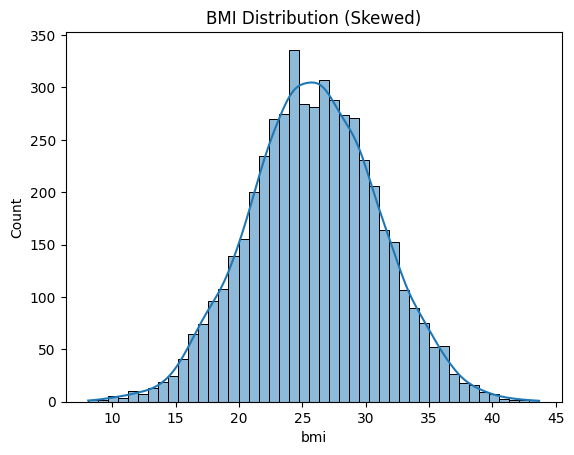

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt
skew_bmi = df['bmi'].skew()
print("BMI Skewness:", skew_bmi)
sns.histplot(df['bmi'], kde=True)
plt.title("BMI Distribution (Skewed)")
plt.show()


In [17]:
import numpy as np

df['bmi'] = np.where(df['bmi'] < 13, 13, df['bmi'])


In [18]:
df.alpha_fetoprotein_level.describe()


,alpha_fetoprotein_level
count,5000.000000
mean,15.109424
std,15.196809
min,0.000000
25%,4.357500
50%,10.340000
75%,21.010000
max,136.800000


In [19]:
import pandas as pd
import numpy as np
col = 'alpha_fetoprotein_level'
Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
df[col] = np.clip(df[col], lower, upper)


In [20]:
df.liver_function_score.describe()

,liver_function_score
count,5000.000000
mean,65.203900
std,14.875477
min,5.500000
25%,54.800000
50%,65.200000
75%,75.200000
max,115.700000


In [21]:
col = 'liver_function_score'
Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
df[col] = np.clip(df[col], lower, upper)


In [22]:
import pandas as pd
!pip install catboost
from catboost import CatBoostClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 8.4 MB/s eta 0:00:00


In [23]:
X = df.drop('liver_cancer', axis=1)
y = df['liver_cancer']

categorical_features = ['gender', 'alcohol_consumption', 'smoking_status', 'physical_activity_level']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [24]:
model = CatBoostClassifier(
    iterations=200,
    learning_rate=0.03,
    depth=4,
    l2_leaf_reg=5,
    eval_metric='AUC',
    cat_features=categorical_features,
    early_stopping_rounds=20,
    verbose=50
)

model.fit(X_train, y_train, eval_set=(X_test, y_test))

0:	test: 0.7832188	best: 0.7832188 (0)	total: 61.7ms	remaining: 12.3s
50:	test: 0.9946327	best: 0.9949318 (49)	total: 746ms	remaining: 2.18s
100:	test: 0.9994017	best: 0.9994486 (98)	total: 1.27s	remaining: 1.25s
150:	test: 0.9998475	best: 0.9998592 (142)	total: 1.66s	remaining: 539ms
Stopped by overfitting detector  (20 iterations wait)

bestTest = 0.9999354748
bestIteration = 170

Shrink model to first 171 iterations.


In [25]:
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:,1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, y_pred_proba))


Accuracy: 0.98
ROC AUC: 0.9999354747882401


In [26]:
def test_prediction():
    print("\n--- Patient Risk Assessment Test ---")
    features = ['age', 'gender', 'bmi', 'alcohol_consumption', 'smoking_status',
                'hepatitis_b', 'hepatitis_c', 'liver_function_score',
                'alpha_fetoprotein_level', 'cirrhosis_history',
                'family_history_cancer', 'physical_activity_level', 'diabetes']

    user_input = {}
    for feature in features:
        val = input(f"Enter {feature}: ")
        if feature in ['age', 'bmi', 'liver_function_score', 'alpha_fetoprotein_level',
                       'hepatitis_b', 'hepatitis_c', 'cirrhosis_history',
                       'family_history_cancer', 'diabetes']:
            val = float(val)
        user_input[feature] = [val]

    input_df = pd.DataFrame(user_input)
    # Get probability
    proba = model.predict_proba(input_df)[0, 1]
    percentage = round(proba * 100, 2)

    print(f"\nResult: {percentage}%")

    if percentage < 30:
        status = "Low Risk"
    elif 30 <= percentage < 60:
        status = "Moderate Risk"
    else:
        status = "High Suspicion"

    print(f"Status: {status}")

# Run test
test_prediction()


--- Patient Risk Assessment Test ---
Enter age: 30
Enter gender: Female
Enter bmi: 22
Enter alcohol_consumption: Never
Enter smoking_status: Never
Enter hepatitis_b: 0
Enter hepatitis_c: 0
Enter liver_function_score: 90
Enter alpha_fetoprotein_level: 2.5
Enter cirrhosis_history: 0
Enter family_history_cancer: 0
Enter physical_activity_level: High
Enter diabetes: 0

Result: 0.2%
Status: Low Risk


In [27]:
def test_prediction():
    print("\n--- Patient Risk Assessment Test ---")
    features = ['age', 'gender', 'bmi', 'alcohol_consumption', 'smoking_status',
                'hepatitis_b', 'hepatitis_c', 'liver_function_score',
                'alpha_fetoprotein_level', 'cirrhosis_history',
                'family_history_cancer', 'physical_activity_level', 'diabetes']

    user_input = {}
    for feature in features:
        val = input(f"Enter {feature}: ")
        if feature in ['age', 'bmi', 'liver_function_score', 'alpha_fetoprotein_level',
                       'hepatitis_b', 'hepatitis_c', 'cirrhosis_history',
                       'family_history_cancer', 'diabetes']:
            val = float(val)
        user_input[feature] = [val]

    input_df = pd.DataFrame(user_input)
    # Get probability
    proba = model.predict_proba(input_df)[0, 1]
    percentage = round(proba * 100, 2)

    print(f"\nResult: {percentage}%")

    if percentage < 30:
        status = "Low Risk"
    elif 30 <= percentage < 60:
        status = "Moderate Risk"
    else:
        status = "High Suspicion"

    print(f"Status: {status}")

# Run test
test_prediction()


--- Patient Risk Assessment Test ---
Enter age: 72
Enter gender: Male
Enter bmi: 31
Enter alcohol_consumption: Regular
Enter smoking_status: Current
Enter hepatitis_b: 0
Enter hepatitis_c: 1
Enter liver_function_score: 40
Enter alpha_fetoprotein_level: 38
Enter cirrhosis_history: 1
Enter family_history_cancer: 1
Enter physical_activity_level: Low
Enter diabetes: 1

Result: 99.98%
Status: High Suspicion


In [29]:
# حفظ الموديل
model.save_model("catboost_liver_model.cbm")

print("Model saved successfully! You can find the file in your directory.")

Model saved successfully! You can find the file in your directory.


In [ ]:
"""
from catboost import CatBoostClassifier

model = CatBoostClassifier()
model.load_model("catboost_liver_model.cbm")

print("Model loaded successfully!")
"""